In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv('bank-full.csv', sep=';')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
print("Number of rows and columns:", df.shape)

print("Number of rows:", df.shape[0])

print("Number of columns:", df.shape[1])

Number of rows and columns: (45211, 17)
Number of rows: 45211
Number of columns: 17


In [5]:
print("Column names in the dataset:\n")

print(df.columns.tolist())

Column names in the dataset:

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [6]:
print("Dataset Information:\n")

df.info()

print("\nMissing Values in Each Column:\n")

print(df.isnull().sum())

Dataset Information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB

Missing Values in Each Column:

age          0
job          0
marital      0

In [7]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


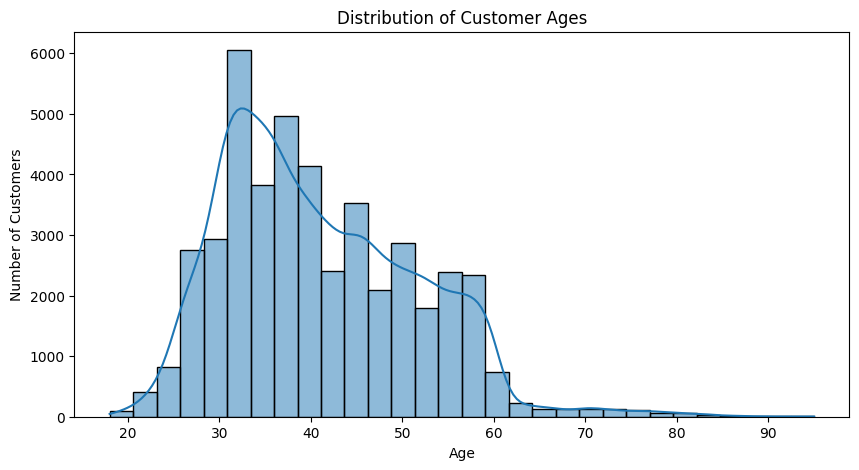

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='age', bins=30, kde=True)

plt.title('Distribution of Customer Ages')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

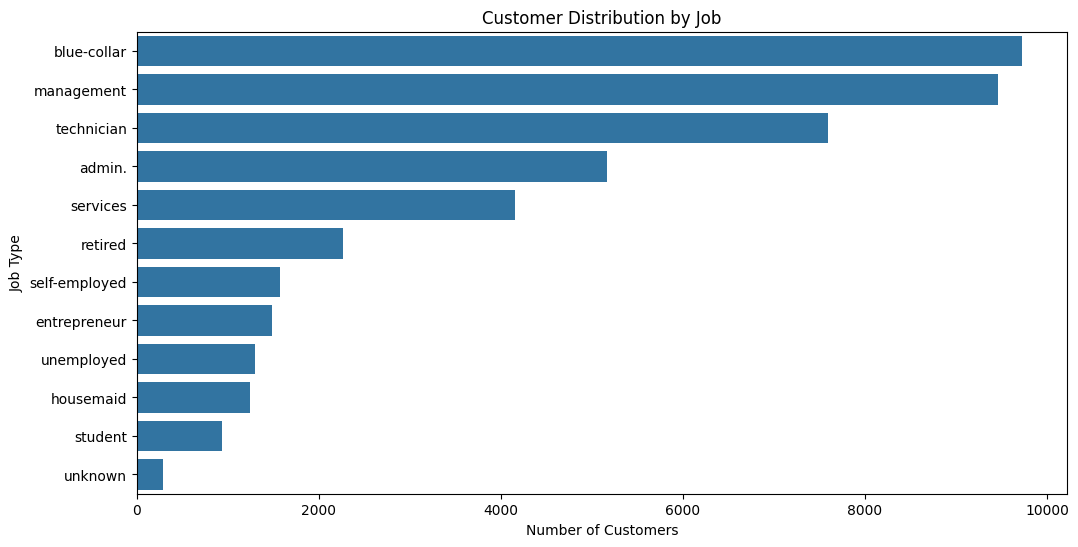

In [9]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y='job',
    order=df['job'].value_counts().index
)

plt.title('Customer Distribution by Job')
plt.xlabel('Number of Customers')
plt.ylabel('Job Type')

plt.show()

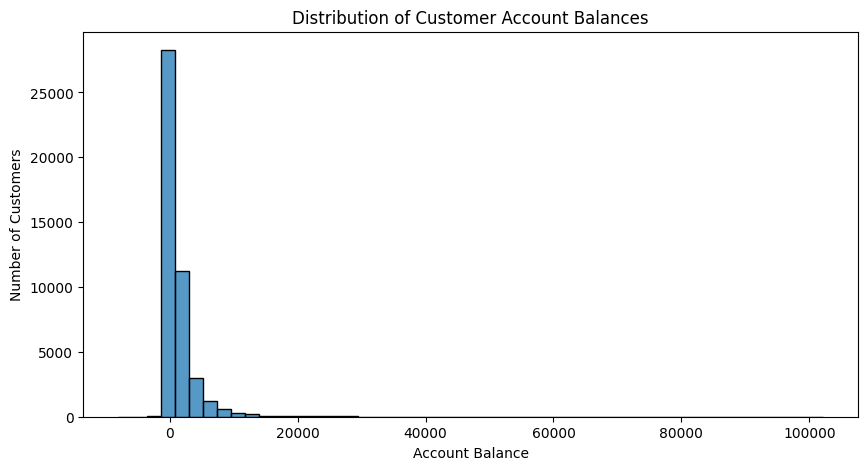

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='balance', bins=50)

plt.title('Distribution of Customer Account Balances')
plt.xlabel('Account Balance')
plt.ylabel('Number of Customers')

plt.show()

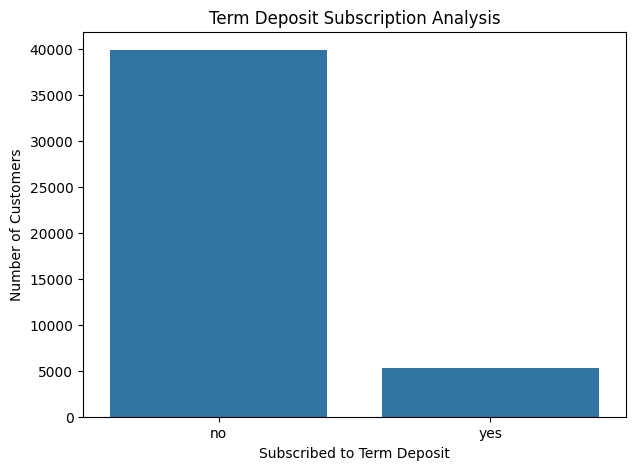

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='y')

plt.title('Term Deposit Subscription Analysis')
plt.xlabel('Subscribed to Term Deposit')
plt.ylabel('Number of Customers')

plt.show()

Subscription Rate by Job Type (%):
y                 no    yes
job                        
admin.         87.80  12.20
blue-collar    92.73   7.27
entrepreneur   91.73   8.27
housemaid      91.21   8.79
management     86.24  13.76
retired        77.21  22.79
self-employed  88.16  11.84
services       91.12   8.88
student        71.32  28.68
technician     88.94  11.06
unemployed     84.50  15.50
unknown        88.19  11.81


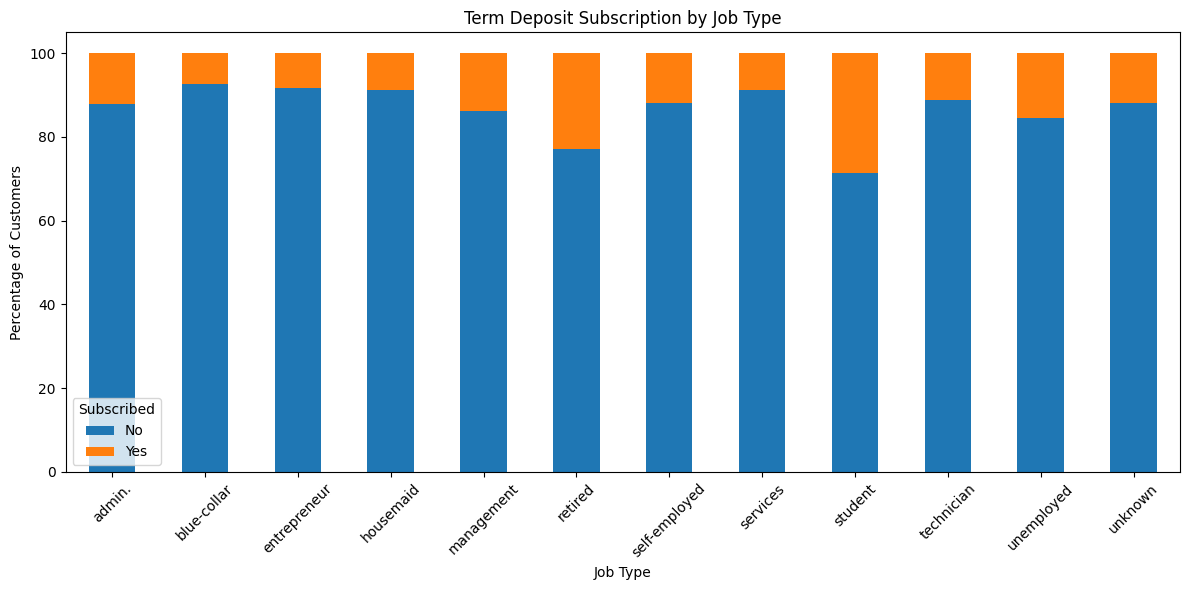

In [12]:
# Calculate subscription rates by job type

job_subscription = pd.crosstab(
    df['job'],
    df['y'],
    normalize='index'
) * 100

print("Subscription Rate by Job Type (%):")
print(job_subscription.round(2))

# Plot subscription rates

job_subscription.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title('Term Deposit Subscription by Job Type')
plt.xlabel('Job Type')
plt.ylabel('Percentage of Customers')
plt.legend(title='Subscribed', labels=['No', 'Yes'])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Subscription Rate by Marital Status (%):
y            no    yes
marital               
divorced  88.05  11.95
married   89.88  10.12
single    85.05  14.95


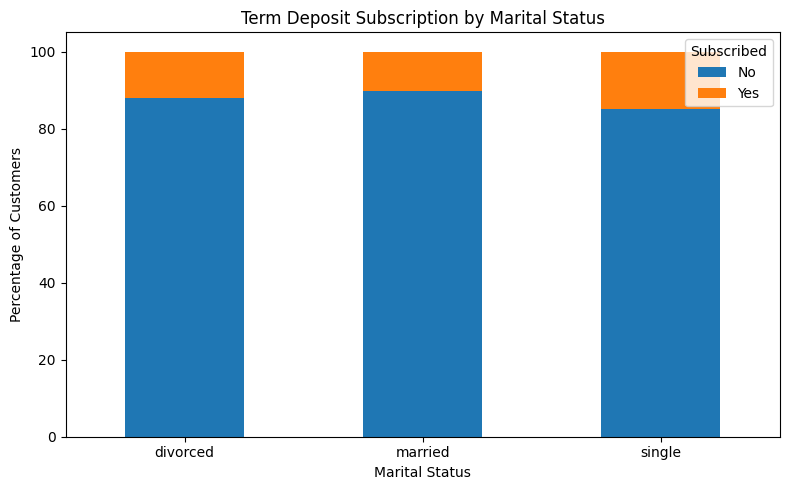

In [13]:
marital_subscription = pd.crosstab(
    df['marital'],
    df['y'],
    normalize='index'
) * 100

print("Subscription Rate by Marital Status (%):")
print(marital_subscription.round(2))

marital_subscription.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)

plt.title('Term Deposit Subscription by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Percentage of Customers')
plt.legend(title='Subscribed', labels=['No', 'Yes'])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Subscription Rate by Education Level (%):
y             no    yes
education              
primary    91.37   8.63
secondary  89.44  10.56
tertiary   84.99  15.01
unknown    86.43  13.57


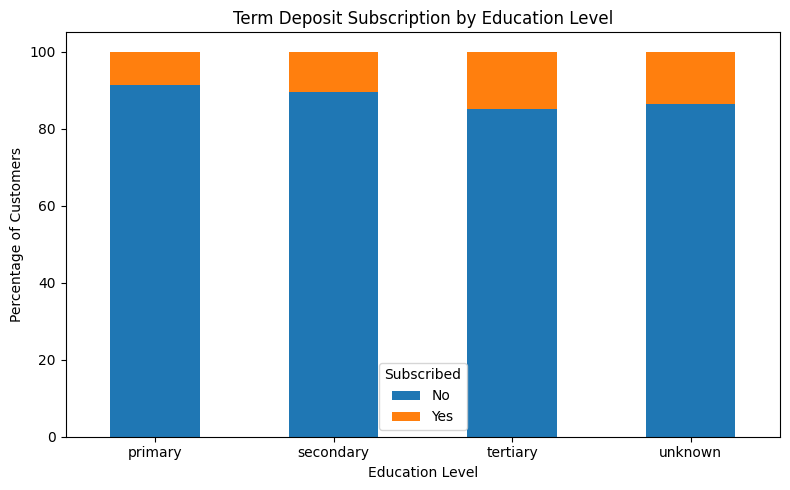

In [14]:
education_subscription = pd.crosstab(
    df['education'],
    df['y'],
    normalize='index'
) * 100

print("Subscription Rate by Education Level (%):")
print(education_subscription.round(2))

education_subscription.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)

plt.title('Term Deposit Subscription by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Percentage of Customers')
plt.legend(title='Subscribed', labels=['No', 'Yes'])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

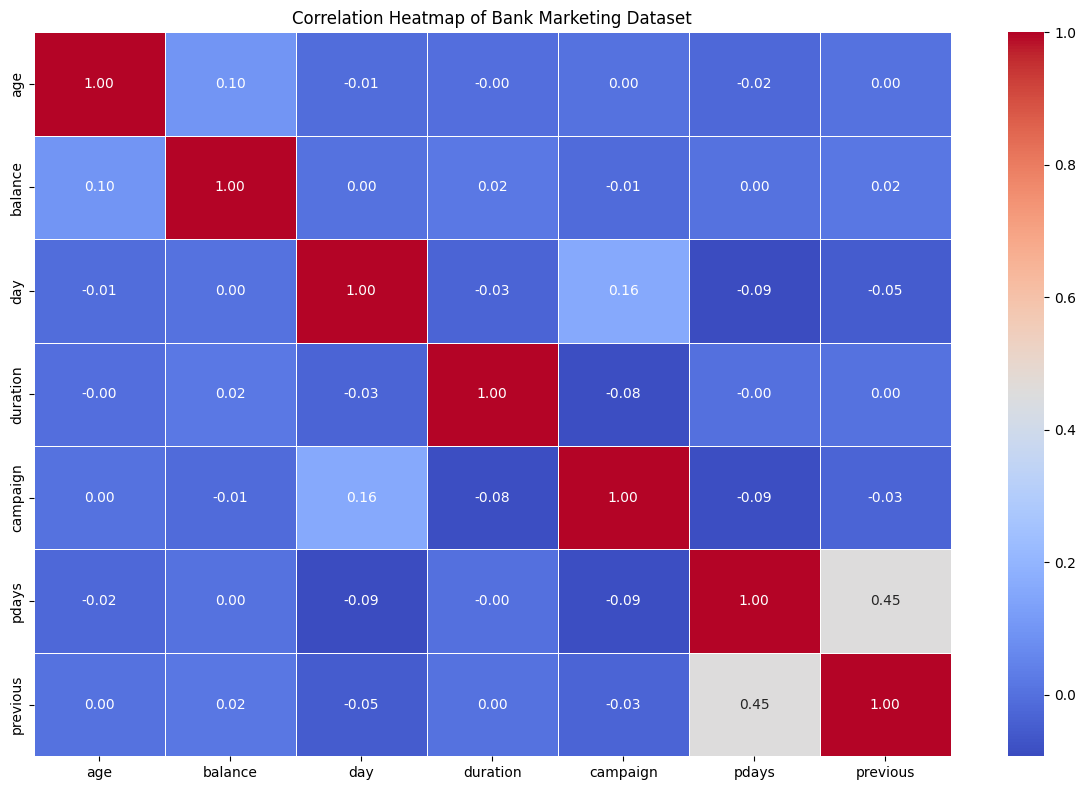

In [15]:
# Select numerical columns
numeric_df = df.select_dtypes(include='number')

# Calculate correlations
correlation_matrix = numeric_df.corr()

# Plot the correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Bank Marketing Dataset')
plt.tight_layout()
plt.show()

Subscription Counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Subscription Percentages:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


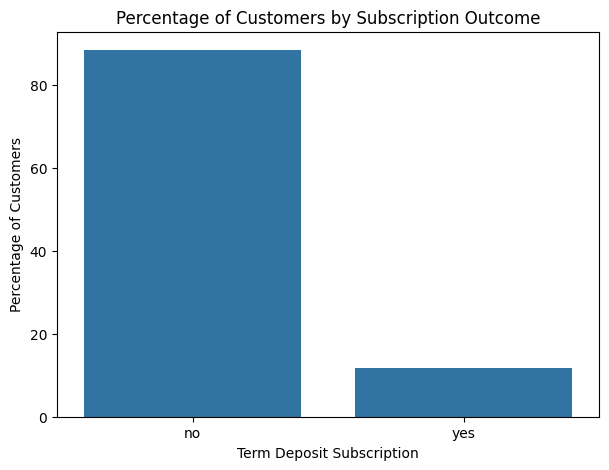

In [16]:
# Count subscription outcomes
subscription_counts = df['y'].value_counts()

print("Subscription Counts:")
print(subscription_counts)

# Calculate subscription percentages
subscription_percentages = (
    df['y'].value_counts(normalize=True) * 100
)

print("\nSubscription Percentages:")
print(subscription_percentages.round(2))

# Plot the results
plt.figure(figsize=(7, 5))

sns.barplot(
    x=subscription_percentages.index,
    y=subscription_percentages.values
)

plt.title('Percentage of Customers by Subscription Outcome')
plt.xlabel('Term Deposit Subscription')
plt.ylabel('Percentage of Customers')

plt.show()

In [17]:
print("=" * 50)
print("BANK MARKETING DATA ANALYSIS: KEY FINDINGS")
print("=" * 50)

print(f"\nTotal customers analyzed: {len(df)}")

print(f"Number of features: {df.shape[1]}")

print(
    f"\nAverage customer age: {df['age'].mean():.2f} years"
)

print(
    f"Average account balance: {df['balance'].mean():.2f}"
)

print(
    f"\nCustomers who subscribed: {(df['y'] == 'yes').sum()}"
)

print(
    f"Customers who did not subscribe: {(df['y'] == 'no').sum()}"
)

print(
    f"\nOverall subscription rate: "
    f"{(df['y'] == 'yes').mean() * 100:.2f}%"
)

print("\nTop 5 job categories by customer count:")

print(df['job'].value_counts().head(5))

print("\nAnalysis completed successfully!")

BANK MARKETING DATA ANALYSIS: KEY FINDINGS

Total customers analyzed: 45211
Number of features: 17

Average customer age: 40.94 years
Average account balance: 1362.27

Customers who subscribed: 5289
Customers who did not subscribe: 39922

Overall subscription rate: 11.70%

Top 5 job categories by customer count:
job
blue-collar    9732
management     9458
technician     7597
admin.         5171
services       4154
Name: count, dtype: int64

Analysis completed successfully!
